# Studenters karaktergjennomsnitt og selvrapporterte depresjon

Vi bruker **multippel lineær regresjon** til å undersøke sammenhengen mellom CGPA og
arbeids-/studietimer, studiepress og økonomisk stress. Deretter bruker vi **logistisk
regresjon** til å klassifisere selvrapportert depresjon med fem forklaringsvariabler:
CGPA, arbeids-/studietimer, studiepress, økonomisk stress og alder.

Kjør cellene i rekkefølge med «Restart Kernel and Run All Cells». Råfilen endres ikke.
Resultattabeller lagres i `resultater/`, og figurene lagres i `figurer/`.
Klyngeanalysen fra første versjon beholdes til slutt som en utforskende tilleggsanalyse.

Kilde: [Student Depression Dataset, Hopesb/Kaggle](https://www.kaggle.com/datasets/hopesb/student-depression-dataset).
`Work/Study Hours` omtales som arbeids-/studietimer. Tidsenhet, utvalgsmetode og
målingen av depresjon må dokumenteres fra kilden før rapporten ferdigstilles.


## 1. Oppsett
Bibliotekene installeres fra `requirements.txt` før notatboken startes, se README.
Vi beholder 75/25-delingen og tilfeldig frø 42 fra den opprinnelige analysen.
Modellene og terskelen 0,5 er fastsatt på forhånd; vi søker ikke etter den beste
modellen på testsettet. Testresultater fra tidligere arbeid er allerede sett,
så dette er en intern, utforskende evaluering og ingen uavhengig ekstern validering.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

DATAFIL = Path('Student_Depression_Dataset.csv')
FIGURER = Path('figurer')
RESULTATER = Path('resultater')
FIGURER.mkdir(exist_ok=True)
RESULTATER.mkdir(exist_ok=True)
FROE = 42
TESTANDEL = 0.25
REG_VARIABLER = ['Work/Study Hours', 'Academic Pressure', 'Financial Stress']
KLASS_VARIABLER = ['CGPA', *REG_VARIABLER, 'Age']
ANALYSEKOLONNER = [*KLASS_VARIABLER, 'Depression']
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.size': 11})

def lagre_tabell(tabell, navn, index=False):
    tabell.to_csv(RESULTATER / f'{navn}.csv', index=index, encoding='utf-8')
    display(tabell)

def lagre_figur(figur, navn):
    figur.tight_layout()
    figur.savefig(FIGURER / navn, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(figur)

def regresjonsmaal(observert, predikert):
    return {'R2': r2_score(observert, predikert),
            'RMSE': np.sqrt(mean_squared_error(observert, predikert))}


## 2. Datakontroll og dokumentert rensing
Vi gjør følgende uten å overskrive råfilen:
1. Avgrenser til rader der `Profession` er `Student` (etter trimming av mellomrom).
2. Fjerner bare helt identiske rådatadubletter; like modellsvar betyr ikke samme person.
3. Gjør analysekolonnene numeriske og rapporterer nye manglende verdier.
4. Bruker komplette observasjoner for alle seks analysekolonner, slik at hovedanalysene
   har samme datagrunnlag. Ingen målverdier eller forklaringsvariabler fylles inn.
5. Fjerner ikke-endelige tall og verdier utenfor de eksplisitte kontrollgrensene under.

CGPA kontrolleres mot 0–10 og skårene mot de forventede kodene. Vi antar ikke at
0 i CGPA eller studiepress betyr manglende: disse beholdes og flagges. For alder
og timer kreves bare positiv alder og ikke-negative timer, siden vi ikke har
grunnlag for strengere grenser. Uvanlige, men mulige svar slettes ikke automatisk.


In [2]:
raw_bytes = DATAFIL.read_bytes()
raw_sha256 = hashlib.sha256(raw_bytes).hexdigest()
raa = pd.read_csv(DATAFIL)
paakrevd = ['id', 'Profession', *ANALYSEKOLONNER]
mangler_kolonner = sorted(set(paakrevd) - set(raa.columns))
if mangler_kolonner:
    raise ValueError(f'Mangler kolonner: {mangler_kolonner}')

df = raa.copy(deep=True)
renselogg = []
def registrer_steg(navn, foer, etter):
    renselogg.append({'steg': navn, 'foer': foer, 'etter': etter, 'utelatt': foer - etter})

foer = len(df)
df = df.loc[df['Profession'].astype('string').str.strip().eq('Student').fillna(False)].copy()
registrer_steg('Avgrensning til studenter', foer, len(df))
foer = len(df)
df = df.drop_duplicates().copy()
registrer_steg('Helt identiske rådatadubletter', foer, len(df))


In [3]:
konvertering = []
for kolonne in ANALYSEKOLONNER:
    antall_manglet = df[kolonne].isna().sum()
    df[kolonne] = pd.to_numeric(df[kolonne], errors='coerce')
    konvertering.append({'variabel': kolonne, 'manglet_foer': int(antall_manglet),
                        'nye_manglende_etter_tallkonvertering': int(df[kolonne].isna().sum() - antall_manglet)})
lagre_tabell(pd.DataFrame(konvertering), 'manglende_verdier')
foer = len(df)
df = df.dropna(subset=ANALYSEKOLONNER).copy()
registrer_steg('Manglende analyseverdier', foer, len(df))


,variabel,manglet_foer,nye_manglende_etter_tallkonvertering
0,CGPA,0,0
1,Work/Study Hours,0,0
2,Academic Pressure,0,0
3,Financial Stress,3,0
4,Age,0,0
5,Depression,0,0


In [4]:
gyldig = pd.DataFrame({
    'CGPA': df['CGPA'].between(0, 10),
    'Work/Study Hours': df['Work/Study Hours'].ge(0),
    'Academic Pressure': df['Academic Pressure'].isin([0, 1, 2, 3, 4, 5]),
    'Financial Stress': df['Financial Stress'].isin([1, 2, 3, 4, 5]),
    'Age': df['Age'].gt(0),
    'Depression': df['Depression'].isin([0, 1]),
}, index=df.index)
gyldig &= np.isfinite(df[gyldig.columns])
lagre_tabell((~gyldig).sum().rename_axis('variabel').reset_index(name='ugyldige_svar'), 'ugyldige_verdier')
foer = len(df)
df = df.loc[gyldig.all(axis=1)].copy()
registrer_steg('Ugyldige eller ikke-endelige analyseverdier', foer, len(df))
df['Depression'] = df['Depression'].astype(int)
if df['id'].isna().any() or df['id'].duplicated().any():
    raise ValueError('ID mangler eller er duplisert. Avklar personidentitet før oppdeling.')
if df.empty or df['Depression'].nunique() != 2:
    raise ValueError('Analysen trenger observasjoner fra begge depresjonsklassene.')

lagre_tabell(pd.DataFrame(renselogg), 'renselogg')
nullflagg = df[['CGPA', 'Academic Pressure']].eq(0)
lagre_tabell(nullflagg.sum().rename_axis('variabel').reset_index(name='antall_nullverdier'), 'nullverdier')
print(f'Rådata: {len(raa)} rader. Analysegrunnlag: {len(df)} studenter.')
print(f'Råfilens SHA256: {raw_sha256}')


,variabel,ugyldige_svar
0,CGPA,0
1,Work/Study Hours,0
2,Academic Pressure,0
3,Financial Stress,0
4,Age,0
5,Depression,0


,steg,foer,etter,utelatt
0,Avgrensning til studenter,27901,27870,31
1,Helt identiske rådatadubletter,27870,27870,0
2,Manglende analyseverdier,27870,27867,3
3,Ugyldige eller ikke-endelige analyseverdier,27867,27867,0


,variabel,antall_nullverdier
0,CGPA,9
1,Academic Pressure,9


Rådata: 27901 rader. Analysegrunnlag: 27867 studenter.
Råfilens SHA256: c867f72c4dd25a0e1b08ab809cf971baad76984daf0547c4d367f5ad162495e1


**Les renseloggen:** «utelatt» telles trinnvis, slik at samme rad ikke telles flere
ganger. Manglende verdi og en målt null er forskjellige ting. Tabellen over
nullverdier viser hva vi beholder til følsomhetsanalysen. Råfilen er fortsatt uendret.


## 3. Beskriv dataene
Se særlig på verdiområder, spredning, klassefordelingen og korrelasjoner.
Skårene for press og stress er ordinale. Å bruke dem numerisk antar at ett
trinn betyr det samme over hele skalaen. Korrelasjon viser samvariasjon,
og kan ikke alene påvise årsak. Hele materialet beskrives her; testsettet
brukes ikke til å velge forklaringsvariabler eller justere modellen.


,variabel,count,mean,std,min,25%,50%,75%,max
0,CGPA,27867.0,7.656084,1.470836,0.0,6.29,7.77,8.92,10.0
1,Work/Study Hours,27867.0,7.157534,3.707136,0.0,4.00,8.00,10.00,12.0
2,Academic Pressure,27867.0,3.140740,1.381637,0.0,2.00,3.00,4.00,5.0
3,Financial Stress,27867.0,3.139520,1.437289,1.0,2.00,3.00,4.00,5.0
4,Age,27867.0,25.821007,4.906538,18.0,21.00,25.00,30.00,59.0
5,Depression,27867.0,0.585172,0.492701,0.0,0.00,1.00,1.00,1.0


,Depression,antall,andel
0,0,11560,0.414828
1,1,16307,0.585172


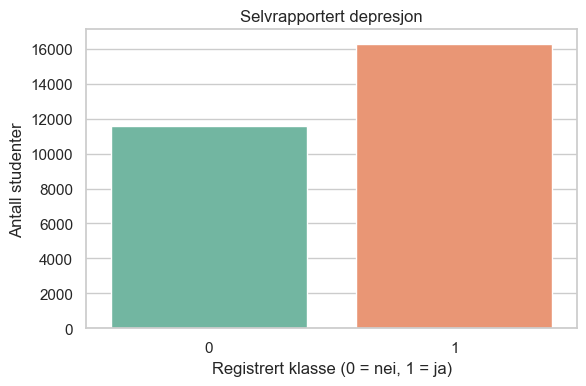

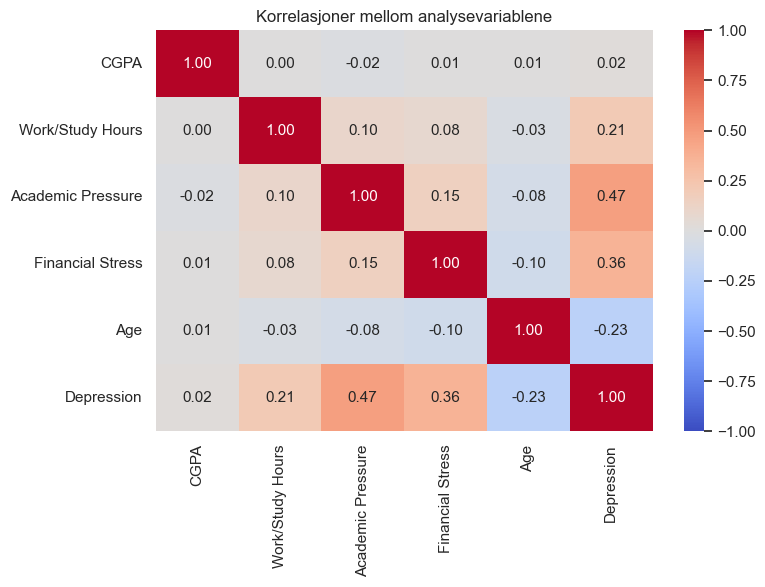

In [5]:
lagre_tabell(df[ANALYSEKOLONNER].describe().T.rename_axis('variabel').reset_index(), 'beskrivende_statistikk')
klasseantall = df['Depression'].value_counts().sort_index()
klasseoversikt = klasseantall.rename_axis('Depression').reset_index(name='antall')
klasseoversikt['andel'] = klasseoversikt['antall'] / len(df)
lagre_tabell(klasseoversikt, 'klassefordeling')
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Depression', hue='Depression', palette='Set2', legend=False, ax=ax)
ax.set(title='Selvrapportert depresjon', xlabel='Registrert klasse (0 = nei, 1 = ja)', ylabel='Antall studenter')
lagre_figur(fig, 'figur1_depresjon_fordeling.png')
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[ANALYSEKOLONNER].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=ax)
ax.set_title('Korrelasjoner mellom analysevariablene')
lagre_figur(fig, 'figur2_korrelasjonsmatrise.png')


## 4. Treningssett og testsett
75 % brukes til tilpasning og 25 % til prediksjonskontroll. Stratifisering gir omtrent
samme klassefordeling i delene. Begge modellene bruker de samme studentene i hver del.
Vi kontrollerer at ingen rad eller person-ID finnes i begge deler.
Fem forklaringsvariabler krever at begge utfallsklassene er godt representert i
treningssettet. Tabellen viser datamengden, men beviser ikke representativitet,
uavhengighet eller god modelltilpasning.


In [6]:
tren, test = train_test_split(df, test_size=TESTANDEL, random_state=FROE, stratify=df['Depression'])
assert set(tren.index).isdisjoint(test.index)
assert set(tren['id']).isdisjoint(test['id'])
assert len(tren) + len(test) == len(df)
klasse_per_del = pd.DataFrame({
    'trening': tren['Depression'].value_counts(),
    'test': test['Depression'].value_counts(),
}).reindex([0, 1]).rename_axis('Depression').reset_index()
lagre_tabell(klasse_per_del, 'klassefordeling_trening_test')
print(f'Trening: {len(tren)}. Test: {len(test)}. Klassifikasjon: {len(KLASS_VARIABLER)} forklaringsvariabler.')
print(f'Minste treningsklasse har {int(klasse_per_del["trening"].min())} observasjoner.')


,Depression,trening,test
0,0,8670,2890
1,1,12230,4077


Trening: 20900. Test: 6967. Klassifikasjon: 5 forklaringsvariabler.
Minste treningsklasse har 8670 observasjoner.


**Vurder datagrunnlaget:** Sammenlign antall observasjoner i hver treningsklasse med
fem forklaringsvariabler. Det er ikke antall variabler alene som avgjør om modellen
er god; se også på variasjon i variablene, modelltilpasning og feiltyper på testsettet.


## 5. Multippel lineær regresjon: CGPA
Vi bruker modellen
\[
CGPA_i=\beta_0+\beta_1 timer_i+\beta_2 studiepress_i+\beta_3 økonomisk\ stress_i+\varepsilon_i.
\]
OLS (minste kvadraters metode) velger koeffisientene som minimerer summen av kvadrerte
residualer. Koeffisientene tolkes når de andre forklaringsvariablene holdes faste.
Modellen tilpasses **treningssettet**. Tabellen viser klassiske OLS-intervaller og
p-verdier; gyldigheten avhenger av forutsetningene som undersøkes nedenfor.
Normalfordeling gjelder feilene, ikke at forklaringsvariablene må være normalfordelte.


In [7]:
X_tren = sm.add_constant(tren[REG_VARIABLER], has_constant='add')
X_test = sm.add_constant(test[REG_VARIABLER], has_constant='add')
ols = sm.OLS(tren['CGPA'], X_tren).fit()
intervall = ols.conf_int()
koeffisienter = pd.DataFrame({
    'variabel': ols.params.index, 'estimat': ols.params.to_numpy(),
    'standardfeil': ols.bse.to_numpy(), 'p_verdi': ols.pvalues.to_numpy(),
    'KI_95_nedre': intervall[0].to_numpy(), 'KI_95_ovre': intervall[1].to_numpy(),
})
lagre_tabell(koeffisienter, 'regresjon_koeffisienter')
print(ols.summary())


,variabel,estimat,standardfeil,p_verdi,KI_95_nedre,KI_95_ovre
0,const,7.674315,0.035640,0.000000,7.604458,7.744173
1,Work/Study Hours,0.002909,0.002759,0.291749,-0.002499,0.008318
2,Academic Pressure,-0.025123,0.007500,0.000810,-0.039823,-0.010423
3,Financial Stress,0.012676,0.007194,0.078059,-0.001424,0.026776


                            OLS Regression Results                            
Dep. Variable:                   CGPA   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     4.542
Date:                Tue, 10 Nov 2026   Prob (F-statistic):            0.00347
Time:                        09:51:52   Log-Likelihood:                -37724.
No. Observations:               20900   AIC:                         7.546e+04
Df Residuals:                   20896   BIC:                         7.549e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 7.6743      0.03

In [8]:
pred_reg_test = ols.predict(X_test)
reg_testtabell = pd.DataFrame([
    {'modell': 'Lineær regresjon', **regresjonsmaal(test['CGPA'], pred_reg_test)},
    {'modell': 'Treningsgjennomsnitt', **regresjonsmaal(test['CGPA'], np.repeat(tren['CGPA'].mean(), len(test)))},
])
lagre_tabell(reg_testtabell, 'regresjon_test')
print(f'R² på trening: {ols.rsquared:.6f}. Justert R²: {ols.rsquared_adj:.6f}.')
print('RMSE måles i CGPA-poeng. Negativ test-R² betyr dårligere enn testsettets gjennomsnitt.')


,modell,R2,RMSE
0,Lineær regresjon,3.697423e-04,1.468062
1,Treningsgjennomsnitt,-2.135335e-07,1.468334


R² på trening: 0.000652. Justert R²: 0.000508.
RMSE måles i CGPA-poeng. Negativ test-R² betyr dårligere enn testsettets gjennomsnitt.


In [9]:
display(Markdown(
    f'**Tolkning av CGPA-modellen:** R² på trening er {ols.rsquared:.6f}, '
    f'altså {100 * ols.rsquared:.3f} % forklart variasjon. '
    f'Test-R² er {reg_testtabell.loc[0, "R2"]:.6f}, og RMSE er '
    f'{reg_testtabell.loc[0, "RMSE"]:.4f} mot referansens {reg_testtabell.loc[1, "RMSE"]:.4f} CGPA-poeng. '
    'For dette datasettet er forklaringskraften svært lav, og prediksjonsgevinsten er svært liten. '
    f'Studiepress har estimat {ols.params["Academic Pressure"]:.4f} per skalatrinn og '
    f'klassisk p-verdi {ols.pvalues["Academic Pressure"]:.5f}. '
    'Den lille p-verdien betyr ikke at sammenhengen er stor eller årsaksmessig. '
    'P-verdi og konfidensintervall må vurderes sammen med residualkontrollene.'
))


**Tolkning av CGPA-modellen:** R² på trening er 0.000652, altså 0.065 % forklart variasjon. Test-R² er 0.000370, og RMSE er 1.4681 mot referansens 1.4683 CGPA-poeng. For dette datasettet er forklaringskraften svært lav, og prediksjonsgevinsten er svært liten. Studiepress har estimat -0.0251 per skalatrinn og klassisk p-verdi 0.00081. Den lille p-verdien betyr ikke at sammenhengen er stor eller årsaksmessig. P-verdi og konfidensintervall må vurderes sammen med residualkontrollene.

## 6. Regresjonskontroller
**Residual = observert CGPA minus predikert CGPA.** En passende lineær modell bør
ikke etterlate en systematisk kurve, og residualenes spredning bør være omtrent
konstant. QQ-plott sammenligner residualfordelingen med en normalfordeling.
Avvik betyr at de klassiske intervallene må tolkes med varsomhet; et stort datasett
gjør ikke modellforutsetningene automatisk riktige.

Uavhengighet må vurderes fra innsamlingen. Unike ID-er beviser ikke at studenter fra
samme miljø er uavhengige. Ingen automatisk normalitetstest brukes som fasit.


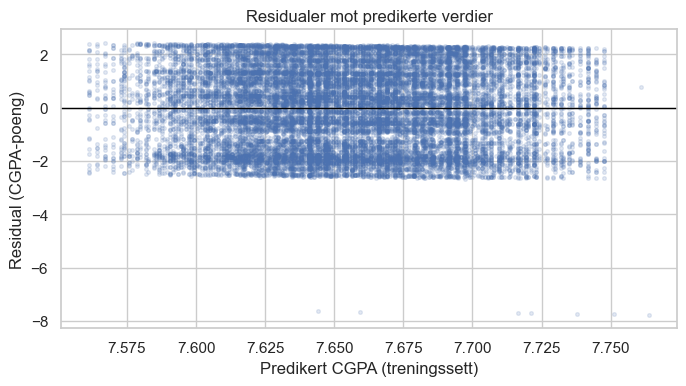

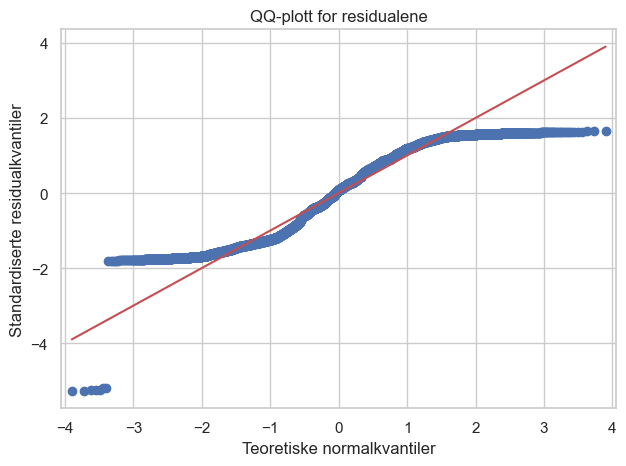

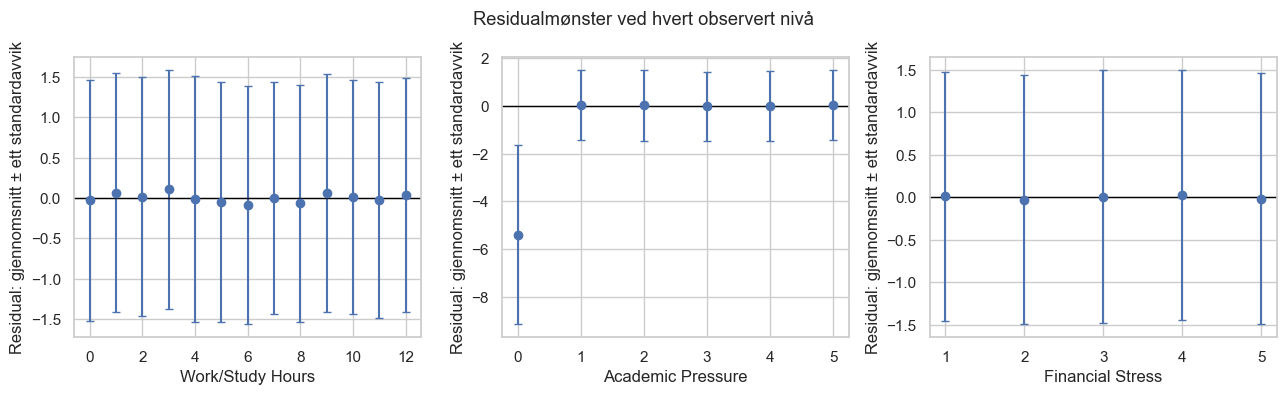

In [10]:
residualer = ols.resid
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(ols.fittedvalues, residualer, s=7, alpha=0.15, rasterized=True)
ax.axhline(0, color='black', linewidth=1)
ax.set(xlabel='Predikert CGPA (treningssett)', ylabel='Residual (CGPA-poeng)', title='Residualer mot predikerte verdier')
lagre_figur(fig, 'figur5_residualer.png')

fig = sm.qqplot(residualer, line='s', fit=True)
fig.axes[0].set(title='QQ-plott for residualene', xlabel='Teoretiske normalkvantiler', ylabel='Standardiserte residualkvantiler')
lagre_figur(fig, 'figur6_qq.png')

fig, akser = plt.subplots(1, 3, figsize=(13, 4))
for ax, variabel in zip(akser, REG_VARIABLER):
    grupper = pd.DataFrame({'x': tren[variabel], 'residual': residualer}).groupby('x')['residual']
    oppsummering = grupper.agg(['mean', 'std'])
    ax.errorbar(oppsummering.index, oppsummering['mean'], yerr=oppsummering['std'], fmt='o', capsize=3)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(xlabel=variabel, ylabel='Residual: gjennomsnitt ± ett standardavvik')
fig.suptitle('Residualmønster ved hvert observert nivå')
lagre_figur(fig, 'figur7_residualer_per_variabel.png')


### Samvariasjon og innflytelsesrike observasjoner
VIF beskriver hvor mye en forklaringsvariabel kan forklares av de andre. En verdi
nær 1 tyder på lite multikollinearitet; VIF er ingen test av årsakssammenheng.
Cook-avstand beskriver hvor mye en observasjon kan påvirke den tilpassede modellen.
Grensen 4/n er bare et signal om å undersøke nærmere. Vi sletter ingen observasjoner
automatisk ut fra Cook-avstand, residualstørrelse eller ønsket resultat.


,variabel,VIF
0,Work/Study Hours,1.012909
1,Academic Pressure,1.031769
2,Financial Stress,1.028689


,id,Work/Study Hours,Academic Pressure,Financial Stress,CGPA,residual,standardisert_residual,leverage,cook_avstand
26719,134830,0.0,0.0,5.0,0.00,-7.737697,-5.260658,0.000590,0.004086
20913,105773,9.0,0.0,5.0,0.00,-7.763880,-5.278084,0.000448,0.003122
25746,129756,9.0,0.0,4.0,0.00,-7.751203,-5.269239,0.000362,0.002515
14855,75007,3.0,0.0,3.0,0.00,-7.721072,-5.248702,0.000342,0.002354
11489,58062,11.0,5.0,5.0,0.00,-7.644082,-5.196065,0.000226,0.001526
21805,110097,10.0,1.0,3.0,0.00,-7.716313,-5.245108,0.000205,0.001408
10407,52737,12.0,3.0,2.0,0.00,-7.659208,-5.206198,0.000169,0.001144
17873,90436,0.0,5.0,1.0,5.09,-2.471376,-1.680114,0.000460,0.000325
13265,67277,1.0,1.0,5.0,5.10,-2.615483,-1.778033,0.000405,0.000320
4941,24768,0.0,5.0,1.0,5.16,-2.401376,-1.632526,0.000460,0.000307


Antall over veiledende Cook-grense 4/n: 280 av 20900.


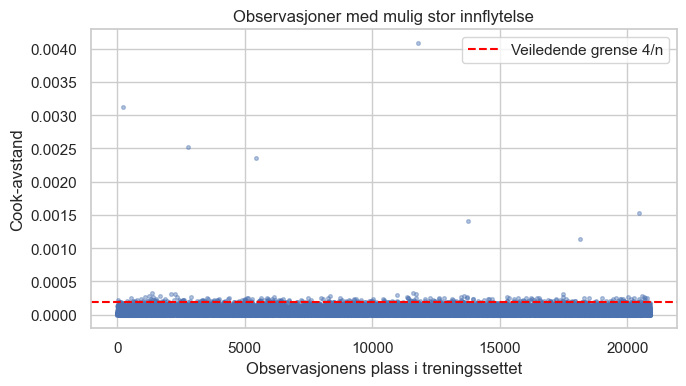

In [11]:
vif = pd.DataFrame({
    'variabel': REG_VARIABLER,
    'VIF': [variance_inflation_factor(X_tren.to_numpy(), i + 1) for i in range(len(REG_VARIABLER))],
})
lagre_tabell(vif, 'regresjon_vif')
innflytelse = ols.get_influence()
cook = innflytelse.cooks_distance[0]
kontroll = tren[['id', *REG_VARIABLER, 'CGPA']].copy()
kontroll['residual'] = residualer
kontroll['standardisert_residual'] = innflytelse.resid_studentized_internal
kontroll['leverage'] = innflytelse.hat_matrix_diag
kontroll['cook_avstand'] = cook
lagre_tabell(kontroll.nlargest(10, 'cook_avstand'), 'regresjon_innflytelse_topp10')
print(f'Antall over veiledende Cook-grense 4/n: {(cook > 4 / len(tren)).sum()} av {len(tren)}.')
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(np.arange(len(tren)), cook, s=7, alpha=0.4)
ax.axhline(4 / len(tren), color='red', linestyle='--', label='Veiledende grense 4/n')
ax.set(xlabel='Observasjonens plass i treningssettet', ylabel='Cook-avstand', title='Observasjoner med mulig stor innflytelse')
ax.legend()
lagre_figur(fig, 'figur8_cook.png')


In [12]:
display(Markdown(
    '**Tolkning av diagnostikken for denne kjøringen:** QQ-plottet har en tydelig S-form, '
    'og nullverdier i CGPA gir store negative residualer. Normalfordeling er derfor '
    'ikke godt støttet av plottet. Residualspredningen er nokså lik over de positive '
    'nivåene av studiepress og de observerte nivåene av timer og økonomisk stress; '
    'gruppen med studiepress 0 skiller seg tydelig ut. Dette er en visuell vurdering, '
    'ikke et bevis for konstant feilvarians eller linearitet. '
    f'VIF ligger mellom {vif["VIF"].min():.3f} og {vif["VIF"].max():.3f}, '
    'så sterk multikollinearitet ser ikke ut til å forklare den lave forklaringskraften. '
    'CGPA-nullene dominerer de største Cook-avstandene. De beholdes i hovedanalysen '
    'og undersøkes i følsomhetsanalysen. Uavhengighet kan ikke avgjøres fra disse figurene.'
))


**Tolkning av diagnostikken for denne kjøringen:** QQ-plottet har en tydelig S-form, og nullverdier i CGPA gir store negative residualer. Normalfordeling er derfor ikke godt støttet av plottet. Residualspredningen er nokså lik over de positive nivåene av studiepress og de observerte nivåene av timer og økonomisk stress; gruppen med studiepress 0 skiller seg tydelig ut. Dette er en visuell vurdering, ikke et bevis for konstant feilvarians eller linearitet. VIF ligger mellom 1.013 og 1.032, så sterk multikollinearitet ser ikke ut til å forklare den lave forklaringskraften. CGPA-nullene dominerer de største Cook-avstandene. De beholdes i hovedanalysen og undersøkes i følsomhetsanalysen. Uavhengighet kan ikke avgjøres fra disse figurene.

## 7. Logistisk regresjon med fem forklaringsvariabler
Responsen er `Depression` (0/1). Modellen beregner en sannsynlighet mellom 0 og 1.
En sannsynlighet på minst 0,5 gir predikert klasse 1. Modellen bruker **CGPA, timer,
studiepress, økonomisk stress og alder**. CGPA er her en forklaringsvariabel; i
lineær regresjon var CGPA responsen. «Fem forklaringsvariabler» er mer presist enn
«fem parametere», siden skjæringspunktet også er en modellparameter.

Standardisering og modell er samlet i en pipeline. Skaleringen læres bare fra
treningssettet. Vi beholder scikit-learns L2-regularisering med C=1 fra første versjon.
Logistisk regresjon forutsetter ikke normalfordelte residualer, men en lineær
sammenheng mellom forklaringsvariablene og log-odds, samt uavhengige observasjoner.
Skårene brukes numerisk med samme antakelse om like skalatrinn som i OLS.


,modell,noyaktighet,sensitivitet,spesifisitet,TN,FP,FN,TP
0,"Logistisk regresjon, fem variabler",0.783838,0.835909,0.710381,2053,837,669,3408
1,Vanligste treningsklasse,0.585187,1.000000,0.000000,0,2890,0,4077


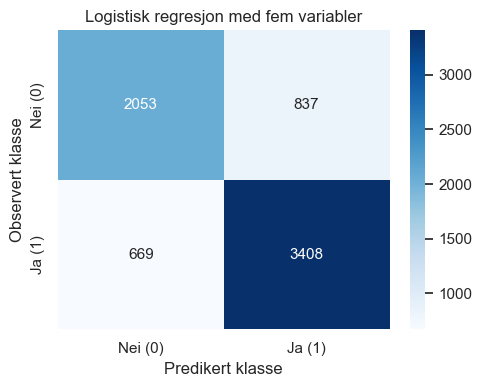

In [13]:
klassifikator = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, random_state=FROE))
klassifikator.fit(tren[KLASS_VARIABLER], tren['Depression'])
sannsynlighet = klassifikator.predict_proba(test[KLASS_VARIABLER])[:, 1]
pred_klass_test = (sannsynlighet >= 0.5).astype(int)
referanse = DummyClassifier(strategy='most_frequent').fit(tren[KLASS_VARIABLER], tren['Depression'])
pred_referanse = referanse.predict(test[KLASS_VARIABLER])

def klassifikasjonsmaal(observert, predikert):
    matrise = confusion_matrix(observert, predikert, labels=[0, 1])
    tn, fp, fn, tp = matrise.ravel()
    return {'noyaktighet': accuracy_score(observert, predikert),
            'sensitivitet': tp / (tp + fn) if tp + fn else np.nan,
            'spesifisitet': tn / (tn + fp) if tn + fp else np.nan,
            'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

klass_testtabell = pd.DataFrame([
    {'modell': 'Logistisk regresjon, fem variabler', **klassifikasjonsmaal(test['Depression'], pred_klass_test)},
    {'modell': 'Vanligste treningsklasse', **klassifikasjonsmaal(test['Depression'], pred_referanse)},
])
lagre_tabell(klass_testtabell, 'klassifikasjon_test')
cm = confusion_matrix(test['Depression'], pred_klass_test, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Nei (0)', 'Ja (1)'], yticklabels=['Nei (0)', 'Ja (1)'], ax=ax)
ax.set(xlabel='Predikert klasse', ylabel='Observert klasse', title='Logistisk regresjon med fem variabler')
lagre_figur(fig, 'figur3_forvekslingsmatrise.png')


In [14]:
skalering = klassifikator.named_steps['standardscaler']
logit = klassifikator.named_steps['logisticregression']
beta_opprinnelig = logit.coef_[0] / skalering.scale_
odds = pd.DataFrame({'variabel': KLASS_VARIABLER, 'koeffisient_original_enhet': beta_opprinnelig,
                     'oddsratio_per_enhet': np.exp(beta_opprinnelig)})
lagre_tabell(odds, 'klassifikasjon_oddsratio')


,variabel,koeffisient_original_enhet,oddsratio_per_enhet
0,CGPA,0.065623,1.067825
1,Work/Study Hours,0.114760,1.121604
2,Academic Pressure,0.853003,2.346682
3,Financial Stress,0.571345,1.770647
4,Age,-0.104768,0.900533


Sensitivitet er andelen med registrert depresjon som klassifiseres til 1.
Spesifisitet er andelen uten registrert depresjon som klassifiseres til 0.
Referansemodellen gjør det tydelig hvor mye bedre modellen er enn bare å velge den
vanligste klassen. En oddsratio på 2 betyr dobbelt odds per enhetsøkning når de
andre variablene holdes faste, ikke dobbelt sannsynlighet eller to prosentpoeng.
Koeffisientene over er omregnet fra standardisert skala til opprinnelige enheter.

Disse resultatene gjelder den registrerte selvrapporteringen. De viser verken at
faktorene forårsaker depresjon eller at modellen kan brukes til klinisk diagnostikk.


In [15]:
rad = klass_testtabell.iloc[0]
display(Markdown(
    f'**Tolkning av klassifikasjonen:** Modellen klassifiserer {100 * rad["noyaktighet"]:.2f} % '
    f'riktig mot referansens {100 * klass_testtabell.iloc[1]["noyaktighet"]:.2f} %. '
    f'Sensitiviteten er {100 * rad["sensitivitet"]:.2f} %, og spesifisiteten er '
    f'{100 * rad["spesifisitet"]:.2f} %. '
    f'Det gir {int(rad["FN"])} falske negative og {int(rad["FP"])} falske positive '
    f'blant {len(test)} testobservasjoner. Fem forklaringsvariabler tilpasses her på '
    f'{len(tren)} treningsobservasjoner, med {int(klasse_per_del["trening"].min())} '
    'i den minste klassen. Antallet gir et godt beregningsgrunnlag for en enkel modell, '
    'men sier ikke at utvalget er representativt eller at de logistiske antakelsene er oppfylt.'
))


**Tolkning av klassifikasjonen:** Modellen klassifiserer 78.38 % riktig mot referansens 58.52 %. Sensitiviteten er 83.59 %, og spesifisiteten er 71.04 %. Det gir 669 falske negative og 837 falske positive blant 6967 testobservasjoner. Fem forklaringsvariabler tilpasses her på 20900 treningsobservasjoner, med 8670 i den minste klassen. Antallet gir et godt beregningsgrunnlag for en enkel modell, men sier ikke at utvalget er representativt eller at de logistiske antakelsene er oppfylt.

## 8. Følsomhetsanalyse for usikre nullverdier
Gjenta begge hovedmodellene uten rader med null i CGPA eller studiepress, med de
samme modellinnstillingene. Gjenværende personer beholder sin opprinnelige
tilhørighet til trening/test; vi trekker ingen ny oppdeling og endrer ingen terskel.
Tabellene viser utvalgsstørrelse, koeffisienter og evaluering. Både treningsgrunnlaget
og testgrunnlaget endres, så forskjeller i mål skal ikke brukes til å rangere modeller.
Dette undersøker robusthet, ikke om nullverdiene faktisk er feil.


In [16]:
tren_uten_null = tren.loc[tren['CGPA'].gt(0) & tren['Academic Pressure'].gt(0)].copy()
test_uten_null = test.loc[test['CGPA'].gt(0) & test['Academic Pressure'].gt(0)].copy()
assert set(tren_uten_null.index).issubset(tren.index)
assert set(test_uten_null.index).issubset(test.index)
assert set(tren_uten_null['id']).isdisjoint(test_uten_null['id'])
if min(len(tren_uten_null), len(test_uten_null)) == 0:
    raise ValueError('For få observasjoner til følsomhetsanalysen.')
if tren_uten_null['Depression'].nunique() != 2 or test_uten_null['Depression'].nunique() != 2:
    raise ValueError('Følsomhetsanalysen trenger begge klasser i hver del.')
ols_uten_null = sm.OLS(tren_uten_null['CGPA'], sm.add_constant(tren_uten_null[REG_VARIABLER], has_constant='add')).fit()
pred_reg_uten_null = ols_uten_null.predict(sm.add_constant(test_uten_null[REG_VARIABLER], has_constant='add'))
folsomhet = pd.DataFrame([
    {'variant': 'Hovedanalyse', 'n_trening': len(tren), 'n_test': len(test),
     'R2_trening': ols.rsquared, **regresjonsmaal(test['CGPA'], pred_reg_test), **ols.params.to_dict()},
    {'variant': 'Uten null i CGPA eller studiepress', 'n_trening': len(tren_uten_null), 'n_test': len(test_uten_null),
     'R2_trening': ols_uten_null.rsquared, **regresjonsmaal(test_uten_null['CGPA'], pred_reg_uten_null), **ols_uten_null.params.to_dict()},
])
lagre_tabell(folsomhet, 'regresjon_folsomhet_nullverdier')


,variant,n_trening,n_test,R2_trening,R2,RMSE,const,Work/Study Hours,Academic Pressure,Financial Stress
0,Hovedanalyse,20900,6967,0.000652,0.000370,1.468062,7.674315,0.002909,-0.025123,0.012676
1,Uten null i CGPA eller studiepress,20891,6964,0.000804,0.000546,1.462287,7.681376,0.003060,-0.028014,0.013827


In [17]:
klass_uten_null = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, random_state=FROE))
klass_uten_null.fit(tren_uten_null[KLASS_VARIABLER], tren_uten_null['Depression'])
pred_klass_uten_null = (klass_uten_null.predict_proba(test_uten_null[KLASS_VARIABLER])[:, 1] >= 0.5).astype(int)
klass_folsomhet = pd.DataFrame([
    {'variant': 'Hovedanalyse', 'n_trening': len(tren), 'n_test': len(test),
     **klassifikasjonsmaal(test['Depression'], pred_klass_test)},
    {'variant': 'Uten null i CGPA eller studiepress', 'n_trening': len(tren_uten_null), 'n_test': len(test_uten_null),
     **klassifikasjonsmaal(test_uten_null['Depression'], pred_klass_uten_null)},
])
lagre_tabell(klass_folsomhet, 'klassifikasjon_folsomhet_nullverdier')
skala_uten_null = klass_uten_null.named_steps['standardscaler']
beta_uten_null = klass_uten_null.named_steps['logisticregression'].coef_[0] / skala_uten_null.scale_
lagre_tabell(pd.DataFrame({'variabel': KLASS_VARIABLER, 'beta_hovedanalyse': beta_opprinnelig,
                          'beta_uten_null': beta_uten_null, 'oddsratio_uten_null': np.exp(beta_uten_null)}),
             'klassifikasjon_folsomhet_koeffisienter')


,variant,n_trening,n_test,noyaktighet,sensitivitet,spesifisitet,TN,FP,FN,TP
0,Hovedanalyse,20900,6967,0.783838,0.835909,0.710381,2053,837,669,3408
1,Uten null i CGPA eller studiepress,20891,6964,0.783889,0.835623,0.710873,2053,835,670,3406


,variabel,beta_hovedanalyse,beta_uten_null,oddsratio_uten_null
0,CGPA,0.065623,0.066497,1.068758
1,Work/Study Hours,0.114760,0.114718,1.121557
2,Academic Pressure,0.853003,0.854170,2.349423
3,Financial Stress,0.571345,0.570823,1.769722
4,Age,-0.104768,-0.104760,0.900540


In [18]:
display(Markdown(
    f'**Tolkning av følsomhetsanalysen:** Uten nullverdiene beholdes {len(tren_uten_null)} '
    f'av {len(tren)} treningsobservasjoner og {len(test_uten_null)} av {len(test)} testobservasjoner. '
    f'OLS har fortsatt svært lav trenings-R² ({ols_uten_null.rsquared:.6f}). '
    f'Klassifikasjonens nøyaktighet er {100 * klass_folsomhet.iloc[1]["noyaktighet"]:.2f} %, '
    f'mot {100 * klass_folsomhet.iloc[0]["noyaktighet"]:.2f} % i hovedanalysen. '
    'Hovedbildet er dermed stabilt i denne kontrollen. Ulikt testgrunnlag gjør at små '
    'forskjeller i feil ikke skal tolkes som at én rensevariant er en bedre modell.'
))


**Tolkning av følsomhetsanalysen:** Uten nullverdiene beholdes 20891 av 20900 treningsobservasjoner og 6964 av 6967 testobservasjoner. OLS har fortsatt svært lav trenings-R² (0.000804). Klassifikasjonens nøyaktighet er 78.39 %, mot 78.38 % i hovedanalysen. Hovedbildet er dermed stabilt i denne kontrollen. Ulikt testgrunnlag gjør at små forskjeller i feil ikke skal tolkes som at én rensevariant er en bedre modell.

## 9. Utforskende tillegg: den opprinnelige klyngeanalysen
Vi beholder K-means med k=3 og de samme fire variablene fra første versjon. Antallet
er foreløpig et illustrativt valg, ikke et validert optimalt antall. Analysen bruker
hele det rensede materialet, men påvirker ingen valg i hovedmodellene.
`Depression` brukes bare til å beskrive gruppene etterpå, aldri til å lage dem.
Plottet viser to av fire dimensjoner og kan derfor ikke vise alle klyngeforskjellene.
Klyngenumrene er bare etiketter og kan ikke sammenlignes direkte med numrene fra første versjon.


,Klynge,CGPA,Work/Study Hours,Academic Pressure,Financial Stress,antall,depresjonsandel
0,0,7.649567,9.274776,2.723235,1.906530,9051,0.441277
1,1,7.672160,2.407652,2.719217,2.886715,8024,0.397308
2,2,7.649596,8.913454,3.804299,4.361564,10792,0.845534


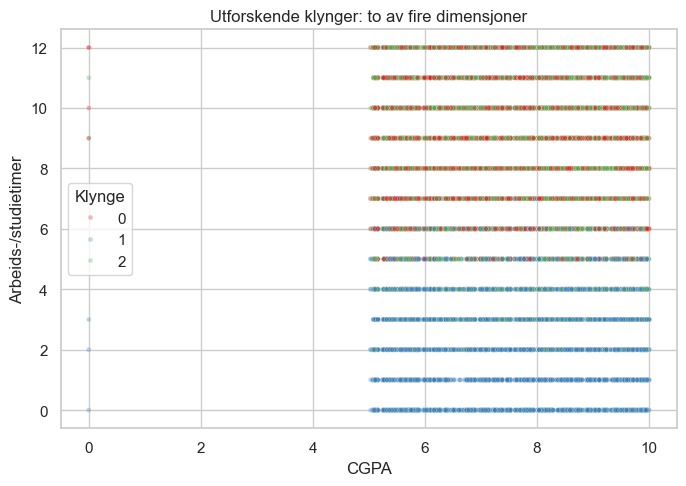

In [19]:
klyngevariabler = ['CGPA', *REG_VARIABLER]
klyngedata = df.copy()
kmeans = make_pipeline(StandardScaler(), KMeans(n_clusters=3, random_state=FROE, n_init=10))
klyngedata['Klynge'] = kmeans.fit_predict(klyngedata[klyngevariabler])
klyngetabell = klyngedata.groupby('Klynge')[klyngevariabler].mean()
klyngetabell['antall'] = klyngedata.groupby('Klynge').size()
klyngetabell['depresjonsandel'] = klyngedata.groupby('Klynge')['Depression'].mean()
lagre_tabell(klyngetabell.reset_index(), 'klynger_utforskende')
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=klyngedata, x='CGPA', y='Work/Study Hours', hue='Klynge', palette='Set1', alpha=0.3, s=12, ax=ax)
ax.set(title='Utforskende klynger: to av fire dimensjoner', xlabel='CGPA', ylabel='Arbeids-/studietimer')
lagre_figur(fig, 'figur4_klynger.png')


**Tolkning av tillegget:** Klyngetabellen beskriver grupper som er laget fra CGPA,
timer og press-/stresskårer. At en gruppe har høyere depresjonsandel, viser en
forskjell i dette materialet. Det dokumenterer verken naturlige studenttyper,
årsakssammenheng eller prediksjonsytelse på nye data.


## 10. Kontroller og tolkning før rapporten skrives
Kontrollene nedenfor bekrefter at råfilen er uendret, at radtall og forvekslingsmatrise
stemmer, at skaleringen er beregnet på treningsdata, og at OLS samsvarer med
scikit-learns uavhengige implementasjon. Dette beviser ikke modellforutsetningene.

Skriv med egne ord: Hvor mye forklarer CGPA-modellen? Er en liten p-verdi også en
stor praktisk sammenheng? Hvilke residualmønstre ser dere? Hvordan står
klassifikasjonen seg mot referansen, og hvilke feil gjør den? Drøft også ordinal
koding, usikre nullverdier, mulige felles miljøer og ukjent representativitet.

KI er brukt til forslag, kodeoppdeling, datakontroll og regresjonsdiagnostikk i denne
PR-en. Gruppen må kontrollere, forstå og deklarere bruken i rapporten.


In [20]:
assert hashlib.sha256(DATAFIL.read_bytes()).hexdigest() == raw_sha256
assert sum(steg['utelatt'] for steg in renselogg) + len(df) == len(raa)
assert np.isfinite(df[ANALYSEKOLONNER].to_numpy()).all()
assert df['Profession'].astype('string').str.strip().eq('Student').all()
assert cm.sum() == len(test)
assert set(tren.index).isdisjoint(test.index)
np.testing.assert_allclose(skalering.mean_, tren[KLASS_VARIABLER].mean().to_numpy())
np.testing.assert_allclose(skalering.var_, tren[KLASS_VARIABLER].var(ddof=0).to_numpy())
np.testing.assert_allclose(skala_uten_null.mean_, tren_uten_null[KLASS_VARIABLER].mean().to_numpy())
for _, rad in klass_testtabell.iterrows():
    antall = rad['TN'] + rad['FP'] + rad['FN'] + rad['TP']
    assert antall == len(test)
    np.testing.assert_allclose(rad['noyaktighet'], (rad['TN'] + rad['TP']) / antall)
    np.testing.assert_allclose(rad['sensitivitet'], rad['TP'] / (rad['TP'] + rad['FN']))
    np.testing.assert_allclose(rad['spesifisitet'], rad['TN'] / (rad['TN'] + rad['FP']))
sklearn_ols = LinearRegression().fit(tren[REG_VARIABLER], tren['CGPA'])
np.testing.assert_allclose(pred_reg_test, sklearn_ols.predict(test[REG_VARIABLER]), atol=1e-10)
assert not np.isnan(klass_testtabell[['noyaktighet', 'sensitivitet', 'spesifisitet']]).any().any()

metadata = {
    'raafil_sha256': raw_sha256, 'n_raa': len(raa), 'n_renset': len(df),
    'n_trening': len(tren), 'n_test': len(test), 'fro': FROE, 'testandel': TESTANDEL,
    'regresjonsvariabler': REG_VARIABLER, 'klassifikasjonsvariabler': KLASS_VARIABLER,
    'regresjon_R2_trening': float(ols.rsquared), 'regresjon_justert_R2_trening': float(ols.rsquared_adj),
    'regresjon_test': reg_testtabell.to_dict(orient='records'),
    'klassifikasjon_test': klass_testtabell.to_dict(orient='records'),
    'regresjon_folsomhet': folsomhet.to_dict(orient='records'),
    'klassifikasjon_folsomhet': klass_folsomhet.to_dict(orient='records'),
    'cook_maks': float(cook.max()), 'vif_maks': float(vif['VIF'].max()),
    'pakkeversjoner': {navn: importlib.metadata.version(navn) for navn in
                      ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scipy', 'scikit-learn', 'statsmodels']},
}
(RESULTATER / 'oppsummering.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2, allow_nan=False) + chr(10), encoding='utf-8')
print('Kontrollene bestod. Tabeller og figurer er lagret.')
display(metadata)


Kontrollene bestod. Tabeller og figurer er lagret.


{'raafil_sha256': 'c867f72c4dd25a0e1b08ab809cf971baad76984daf0547c4d367f5ad162495e1',
 'n_raa': 27901,
 'n_renset': 27867,
 'n_trening': 20900,
 'n_test': 6967,
 'fro': 42,
 'testandel': 0.25,
 'regresjonsvariabler': ['Work/Study Hours',
  'Academic Pressure',
  'Financial Stress'],
 'klassifikasjonsvariabler': ['CGPA',
  'Work/Study Hours',
  'Academic Pressure',
  'Financial Stress',
  'Age'],
 'regresjon_R2_trening': 0.0006516324457733758,
 'regresjon_justert_R2_trening': 0.0005081578524223085,
 'regresjon_test': [{'modell': 'Lineær regresjon',
   'R2': 0.0003697422630208891,
   'RMSE': 1.4680619610207317},
  {'modell': 'Treningsgjennomsnitt',
   'R2': -2.1353353885089632e-07,
   'RMSE': 1.4683335953506682}],
 'klassifikasjon_test': [{'modell': 'Logistisk regresjon, fem variabler',
   'noyaktighet': 0.7838380938711067,
   'sensitivitet': 0.8359087564385578,
   'spesifisitet': 0.7103806228373702,
   'TN': 2053,
   'FP': 837,
   'FN': 669,
   'TP': 3408},
  {'modell': 'Vanligste treni